<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Tenure  MonthlyCharges  Complaints  DataUsage   Contract  Churn
0      52       55.319306           0  62.799833  Two Years      0
1      15       71.777360           1  83.109130   One Year      0
2      72       31.920914           0  19.843361   One Year      0
3      61       63.728160           3  91.804839  Two Years      0
4      21       87.927495           1  55.802295   One Year      0

Hidden Layer Width: 16
Accuracy: 0.7041666666666667
Precision: 0.639344262295082
Recall: 0.4431818181818182
F1 Score: 0.5234899328859061

Hidden Layer Width: 32
Accuracy: 0.725
Precision: 0.671875
Recall: 0.48863636363636365
F1 Score: 0.5657894736842105



Hidden Layer Width: 64
Accuracy: 0.6958333333333333
Precision: 0.6119402985074627
Recall: 0.4659090909090909
F1 Score: 0.5290322580645161

Confusion Matrix:
 [[131  21]
 [ 45  43]]


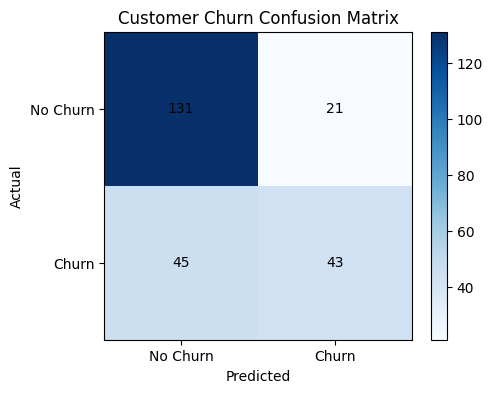

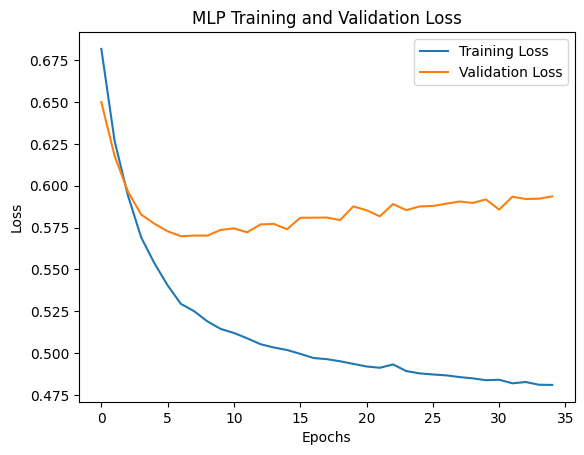

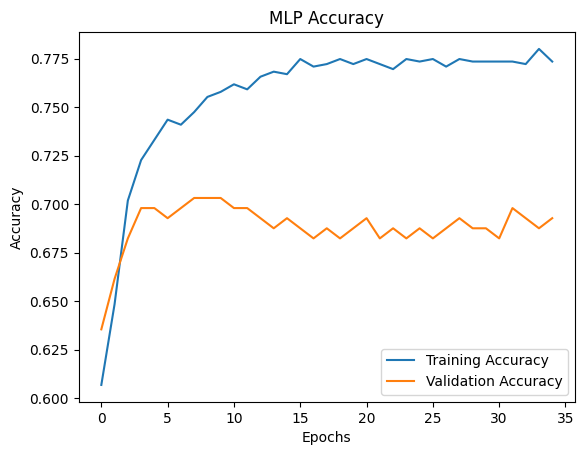

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,precision_score,
    recall_score,f1_score,confusion_matrix
)

np.random.seed(42)

# 1. Generate Customer Churn Dataset
N = 1200

tenure = np.random.randint(1,73,N)
monthly = np.random.uniform(20,150,N)
complaints = np.random.poisson(1.2,N)
usage = np.random.uniform(1,100,N)

contract = np.random.choice(
    ["Monthly","One Year","Two Years"],
    N
)

# Generate Churn Labels
logit = (
    -2 - 0.035*tenure
    + 0.018*monthly
    + 0.55*complaints
    + (contract=="Monthly")*1.0
)

probability = 1/(1+np.exp(-logit))

churn = (
    np.random.random(N)<probability
).astype(int)

data = pd.DataFrame({
    "Tenure":tenure,
    "MonthlyCharges":monthly,
    "Complaints":complaints,
    "DataUsage":usage,
    "Contract":contract,
    "Churn":churn
})

print(data.head())

# 2. Data Preprocessing
X = pd.get_dummies(
    data.drop("Churn",axis=1),
    columns=["Contract"],
    dtype=float
)

Y = data["Churn"]

X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y,test_size=0.2,
    random_state=42,
    stratify=Y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Build MLP Model
results = {}

for width in [16,32,64]:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(width,activation='relu'),
        tf.keras.layers.Dense(width//2,activation='relu'),
        tf.keras.layers.Dense(1,activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # 4. Train Model
    history = model.fit(
        X_train,Y_train,
        epochs=35,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    prediction = (
        model.predict(X_test,verbose=0).ravel()>=0.5
    ).astype(int)

    accuracy = accuracy_score(Y_test,prediction)
    precision = precision_score(Y_test,prediction,zero_division=0)
    recall = recall_score(Y_test,prediction,zero_division=0)
    f1 = f1_score(Y_test,prediction,zero_division=0)

    results[width] = (
        accuracy,precision,recall,f1
    )

    print("\nHidden Layer Width:",width)
    print("Accuracy:",accuracy)
    print("Precision:",precision)
    print("Recall:",recall)
    print("F1 Score:",f1)

    if width == 32:
        best_model = model
        best_prediction = prediction
        best_history = history.history

# 5. Confusion Matrix
cm = confusion_matrix(Y_test,best_prediction)

print("\nConfusion Matrix:\n",cm)

sns_data = cm

plt.figure(figsize=(5,4))
plt.imshow(sns_data,cmap='Blues')
plt.colorbar()

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Churn Confusion Matrix")

plt.xticks([0,1],["No Churn","Churn"])
plt.yticks([0,1],["No Churn","Churn"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],ha='center',va='center')

plt.show()

# Training and Validation Loss
plt.plot(best_history['loss'],label="Training Loss")
plt.plot(best_history['val_loss'],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")
plt.legend()
plt.show()

# Accuracy Graph
plt.plot(best_history['accuracy'],label="Training Accuracy")
plt.plot(best_history['val_accuracy'],label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("MLP Accuracy")
plt.legend()
plt.show()